# Сравнение изменения качества классификации MI и детекции OOD при тестировании на той же сессии, и на другой сессии

Модели обучаются на 75% первой сессии, затем тестируются на 25% первой сессии и на второй сессии.

Результаты: Не видно взаимосвязи между изменением качества классификации MI и детекции OOD.

In [11]:
import os
import sys
from pathlib import Path

DATA_ROOT = Path.home() / "mne_data"

os.environ["MNE_DATA"] = str(DATA_ROOT)
os.environ["MNE_DATASETS_BNCI_PATH"] = str(DATA_ROOT)
os.environ["MNE_DATASETS_ZHOU2016_PATH"] = str(DATA_ROOT)
os.environ["MOABB_DOWNLOAD_PROVIDER"] = "upstream"

EXPERIMENT_DIR = Path("/Users/liza/Projects/vkr/mi-ood")
CACHE_DIR = EXPERIMENT_DIR / "cache"
RESULTS_DIR = EXPERIMENT_DIR / "results"

sys.path.insert(0, str(EXPERIMENT_DIR))
os.chdir(EXPERIMENT_DIR)

print(EXPERIMENT_DIR)

/Users/liza/Projects/vkr/mi-ood


In [12]:
from pipelines import mi_pipelines, ood_pipelines
from processing import *

In [13]:
experiment = "WITHIN-CROSS"
SESSION_TYPES = ("within", "cross")
TEST_SIZE = 0.25
RANDOM_STATE = 42
COMMON_CHANNELS = ["FC3", "FCz", "FC4", "C3", "C4", "CP3", "CP4"]

datasets = [ "TTK", "Zhou2016", "BNCI2014_001",  "Zhou2020" ]


In [14]:
for pipeline in [*mi_pipelines.values(), *ood_pipelines.values()]:
    channel_params = {key: tuple(COMMON_CHANNELS) for key in pipeline.get_params(deep=True) if key.split("__")[-1] == "channel_names"}
    pipeline.set_params(**channel_params)


MI_METHODS = ['ACM+TS+SVM', 'FBCSP+ElasticNet', "Microstates+GB", "VAR+shLDA", "Log-bandpower+shLDA", 'ShallowConvNet', 'EEGNet' ]
OOD_METHODS = ['ACM+TS+OCSVM', 'FBCSP+IsolationForest',  "Log-bandpower+Mahalanobis", "Microstates+LOF", "VAR+Mahalanobis" , 'ShallowConvNet+kNN', 'EEGNet+TempDens']


In [15]:
for dataset in datasets:
    print( dataset )
    subjects = get_subjects(dataset) 

    for subject in subjects:
        data = None

        exp_type = "mi"
        for method, pipeline in mi_pipelines.items():
            if method not in MI_METHODS:
                continue
            results = [{"dataset": dataset, "subject": subject, "experiment": experiment, "experiment_type": f"{exp_type}-{session}", "method": method} for session in SESSION_TYPES]
            if all(result_path(result).exists() for result in results):
                continue
            for result in results:
                result_path(result).unlink(missing_ok=True)
            if data is None:
                data = load_subject_data(dataset, subject, channels=COMMON_CHANNELS, duration=3.0, paired_sessions=True, test_size=TEST_SIZE, random_state=RANDOM_STATE)
            train_data, within_data, cross_data = data
            model = train(train_data, pipeline)
            for result, test_data in zip(results, [within_data, cross_data]):
                result["MI_BA"], result["MI_AUROC"] = MI_metrics(train_data, test_data, pipeline, model=model)
                result.update(n_train=len(train_data[1]), n_test_id=len(test_data[1]), n_test_ood=0, test_size=TEST_SIZE, random_state=RANDOM_STATE)
                save_result(result)
                print(f"{dataset} s{subject} {method} ({result['experiment_type']}): {result['MI_BA']:.3f} {result['MI_AUROC']:.3f}")

        #data = None
        for method, pipeline in ood_pipelines.items():
            if method not in OOD_METHODS:
                continue
            exp_ood = [ ("ood-feet", ("left_foot", "right_foot") if dataset == "TTK" else ("feet",)),
                        ("ood-rest", ("rest",)) ]
            for experiment_type, ood in exp_ood:
                results = [{"dataset": dataset, "subject": subject, "experiment": experiment, "experiment_type": f"{experiment_type}-{session}", "method": method} for session in SESSION_TYPES]
                if all(result_path(result).exists() for result in results):
                    continue
                for result in results:
                    result_path(result).unlink(missing_ok=True)
                #if data is None:
                data = load_subject_data(dataset, subject, channels=COMMON_CHANNELS, duration=3.0, ood_classes=ood, paired_sessions=True, test_size=TEST_SIZE, random_state=RANDOM_STATE )
                train_data, within_data, cross_data = data

                model = train(train_data, pipeline)

                for result, test_data in zip(results, [within_data, cross_data]):
                    result["OOD_AUROC"] = OOD_AUROC(test_data, model)
                    result.update(n_train=len(train_data[1]), n_test_id=int(np.isin(test_data[1], HANDS).sum()), n_test_ood=int((~np.isin(test_data[1], HANDS)).sum()), test_size=TEST_SIZE, random_state=RANDOM_STATE)
                    save_result(result)
                    print(f"{dataset} s{subject} {method} ({result['experiment_type']}): {result['OOD_AUROC']:.3f}")

    display_summary_by_subject(dataset, experiment, experiment_type="mi", metric="MI_BA", methods=MI_METHODS, session_types=SESSION_TYPES)
    display_summary_by_subject(dataset, experiment, experiment_type="mi", metric="MI_AUROC", methods=MI_METHODS, session_types=SESSION_TYPES)
    display_summary_by_subject(dataset, experiment, experiment_type="ood-feet", metric="OOD_AUROC", methods=OOD_METHODS, session_types=SESSION_TYPES)
    display_summary_by_subject(dataset, experiment, experiment_type="ood-rest", metric="OOD_AUROC", methods=OOD_METHODS, session_types=SESSION_TYPES)


TTK


Zhou2016


BNCI2014_001


Zhou2020


In [16]:
display_summary_by_dataset(
    experiment,
    MI_METHODS,
    OOD_METHODS,
    datasets=datasets,
    session_types=SESSION_TYPES,
    experiment_specs=[
        ("MI BA", "mi", "MI_BA"),
        ("MI AUROC", "mi", "MI_AUROC"),
        ("OOD feet", "ood-feet", "OOD_AUROC"),
        ("OOD rest", "ood-rest", "OOD_AUROC"),
    ],
)

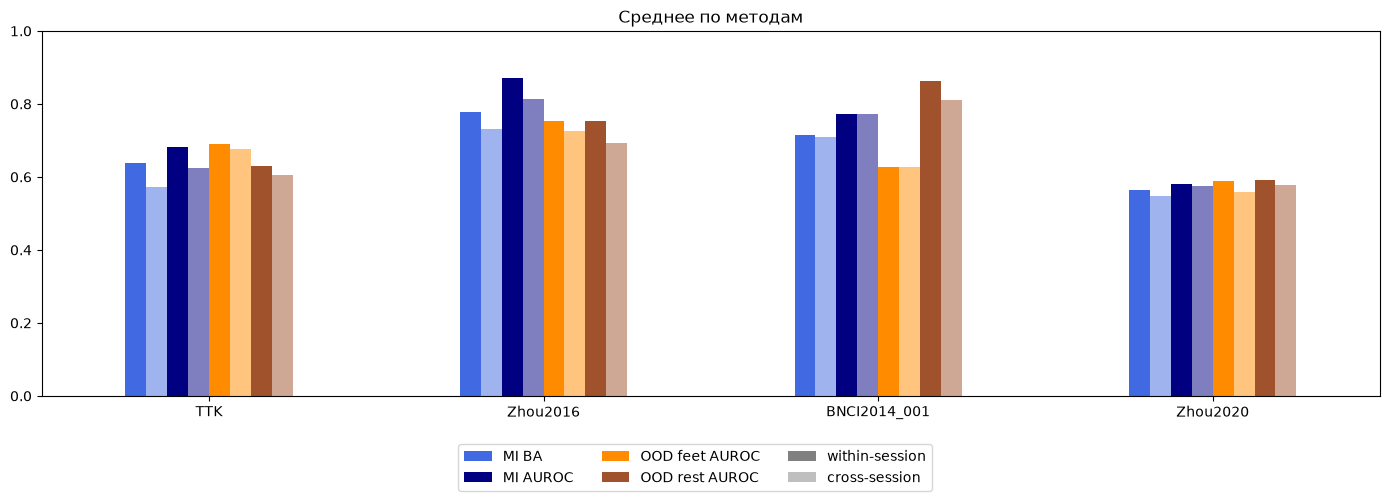

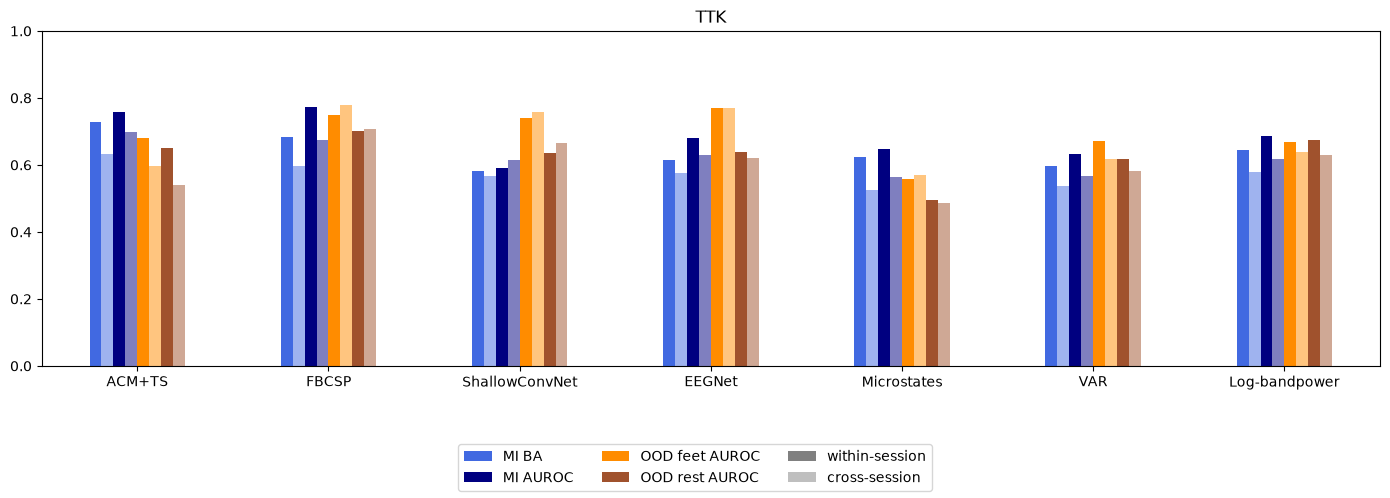

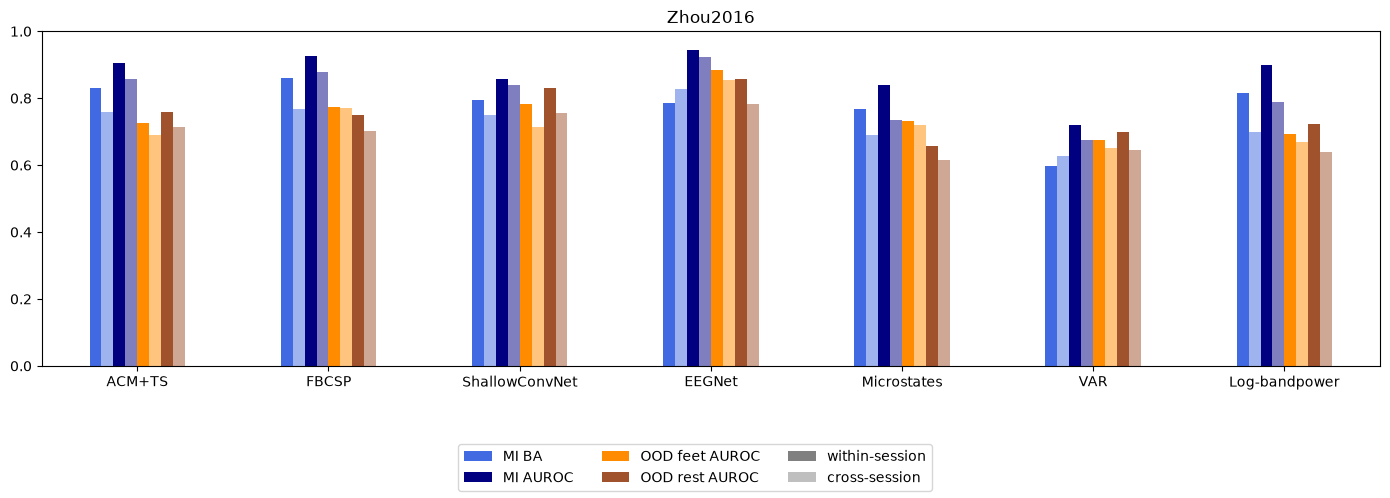

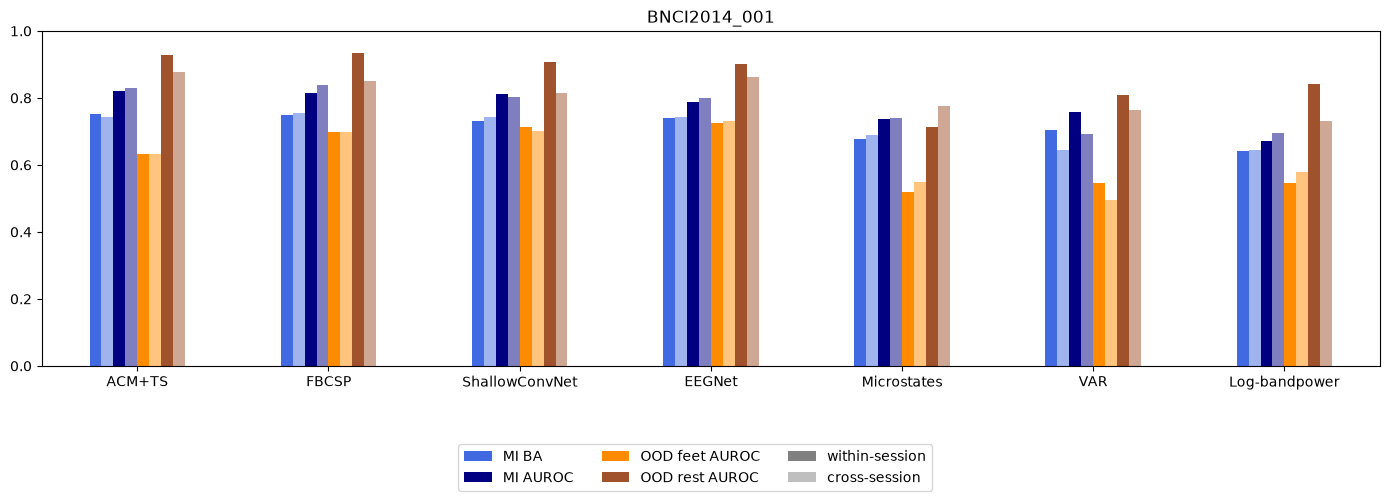

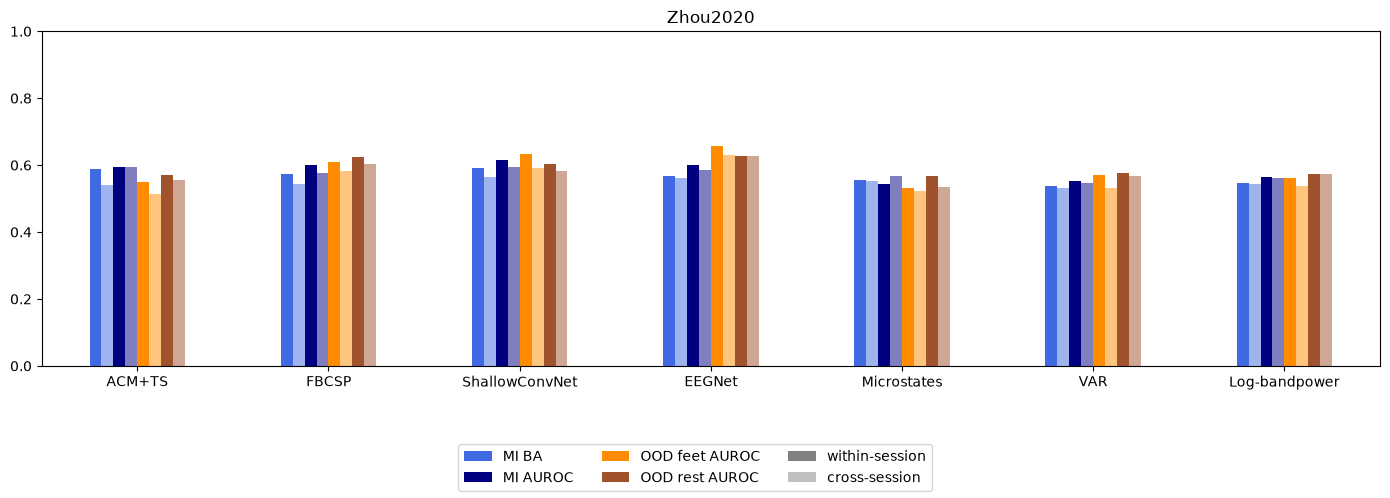

In [17]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

families = ["ACM+TS", "FBCSP", "ShallowConvNet", "EEGNet", "Microstates", "VAR", "Log-bandpower"]
specs = [("MI BA", "mi", "MI_BA"), ("MI AUROC", "mi", "MI_AUROC"), ("OOD feet AUROC", "ood-feet", "OOD_AUROC"), ("OOD rest AUROC", "ood-rest", "OOD_AUROC")]
colors = {
    "MI BA": "royalblue",
    "MI AUROC": "navy",
    "OOD feet AUROC": "darkorange",
    "OOD rest AUROC": "sienna",
}
averages = {}
for dataset in datasets:
    parts = {}
    for title, exp_type, metric in specs:
        table = summarize_results_by_subject(dataset, experiment, experiment_type=exp_type, metric=metric, methods=MI_METHODS if exp_type == "mi" else OOD_METHODS, session_types=SESSION_TYPES)
        if not table.empty:
            parts[title] = table[metric].mean()
    if parts:
        averages[dataset] = pd.concat(parts)

mean_data = pd.DataFrame(averages).T
mean_data = mean_data.reindex(columns=pd.MultiIndex.from_product([[s[0] for s in specs], ["within-session", "cross-session"]]))

ax = mean_data.plot.bar(figsize=(14, 5), title="Среднее по методам", color=[colors[title] for title, session in mean_data.columns], ylim=(0, 1), rot=0, legend=False)
for bars, (title, session) in zip(ax.containers, mean_data.columns):
    for bar in bars: bar.set_alpha(0.5 if session == "cross-session" else 1)

legend = [Patch(facecolor=color, label=title) for title, color in colors.items()]
legend += [Patch(facecolor="gray", alpha=alpha, label=session) for session, alpha in [("within-session", 1), ("cross-session", 0.5)]]
ax.figure.legend(handles=legend, loc="lower center", ncol=3)
plt.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

for dataset in datasets:
    parts = {}
    for title, exp_type, metric in specs:
        table = summarize_results_by_subject(dataset, experiment, experiment_type=exp_type, metric=metric, methods=MI_METHODS if exp_type == "mi" else OOD_METHODS, session_types=SESSION_TYPES)
        if not table.empty:
            table.index = [next(f for f in families if m == f or m.startswith(f + "+")) for m in table.index]
            parts[title] = table[metric].reindex(families)
    if not parts:
        continue
    data = pd.concat(parts, axis=1).dropna(how="all")
    data = data.reindex(columns=[(title, session) for title in parts for session in ["within-session", "cross-session"]])

    ax = data.plot.bar(figsize=(14, 5), title=dataset, color=[colors[title] for title, session in data.columns], ylim=(0, 1), rot=0, legend=False)
    for bars, (title, session) in zip(ax.containers, data.columns):
        for bar in bars: bar.set_alpha(0.5 if session == "cross-session" else 1)

    legend = [Patch(facecolor=color, label=title) for title, color in colors.items()]
    legend += [Patch(facecolor="gray", alpha=alpha, label=session) for session, alpha in [("within-session", 1), ("cross-session", 0.5)]]
    ax.figure.legend(handles=legend, loc="lower center", ncol=3)

    plt.tight_layout(rect=(0, 0.18, 1, 1))
    plt.show()